# Minimal GO gap for equally rough joins

$L(b) = EER(GS_b) - EER(GO_b)$ assumes the joins of $GS_b$ and $GO_b$ are equally rough, so their artefacts cancel. A GO join splices two frames $g + 1$ apart (the gap $g$ skipped between two blocks), a GS join two blocks from anywhere in the span. At gap ratio 1.25, GS's joins are clearly rougher for $b < 32$ (see `transformation.ipynb`). This notebook finds the smallest gap $g$ at which they are about equally rough, for every block size $b$ and both pretrained front-ends.

**Method.** For every utterance of the VoxCeleb1-H trial list (`list_test_hard2.txt`) and every $(b, g)$, the GO and GS inputs are cut exactly as the evaluation cuts them (`src/data/segments.py`: one 2 s window, its gapped span centred in the utterance; GS = GO's blocks in a random order with no block left in place). The roughness of a join is the Euclidean distance between its two frames in the features the model is fed (`segment` normalization's band means cancel in the difference), as `temporal_probes.join_discontinuity` measures it. Utterances shorter than $(b, g)$'s span have no input and are left out for that $(b, g)$, as their trials aren't scored.

**Gap sweep.** Logarithmic, from a quarter of a typical phone length to twice a typical supra-segmental length. Taken here as 80 ms for a phone and 250 ms for a syllable, the shortest supra-segmental unit, so 20 ms to 500 ms. On each front-end's frame grid (10 ms WeSpeaker fbank, 20 ms w2v-BERT 2.0), rounded to whole frames.

**Equally rough.** With ~100k utterances even negligible differences are significant, so the criterion is an effect size: the median GS join distance at most `TOLERANCE` (2%) above GO's. The minimal gap of a $b$ is the smallest swept gap from which on this holds for every larger swept gap with at least `MIN_UTTERANCES` utterances. Also reported, per utterance (GO and GS take the same blocks): the share of utterances whose GS joins are rougher on average (0.5: equally rough).


In [1]:
import os
import sys
import time
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter
import numpy as np
import pandas as pd
import soundfile as sf

ROOT = Path.cwd().parent  # notebook runs from doc/
sys.path.insert(0, str(ROOT))

from src.config import DataConfig, TransformationConfig
from src.data.dataset import featurize_waveform
from src.data.segments import BLOCK_SIZES, gapped_segment, gapped_span, shuffle_blocks
from src.training.trainer import resolved_utterances

In [2]:
PHONE_MS = 80            # typical phone length
SUPRASEGMENTAL_MS = 250  # typical syllable length, the shortest supra-segmental unit
NUM_GAPS = 12            # swept gaps, log-spaced from PHONE_MS / 4 to 2 * SUPRASEGMENTAL_MS
SEGMENT_DURATION = 2.0   # s, as configs/pretrained-*-voxceleb-2s.yaml
TOLERANCE = 0.02         # GS's median join distance at most this much above GO's counts as equally rough
MIN_UTTERANCES = 100     # a (b, g) with fewer utterances long enough for its span isn't judged
FRONT_ENDS = {"wespeaker_fbank": "WeSpeaker fbank (ResNet34, 10 ms frames)", "w2vbert": "w2v-BERT 2.0 (20 ms frames)"}
# Histogram bins of the join distances; larger distances (rare outliers) go into the last bin, which leaves the
# medians and quartiles unchanged.
BIN_WIDTH, MAX_DISTANCE = 0.05, 250.0
NUM_BINS = round(MAX_DISTANCE / BIN_WIDTH)

vox1_root = Path("~/.cache/datasets/voxceleb1").expanduser()
with open(vox1_root / "list_test_hard2.txt") as f:
    paths = sorted({path for line in f for path in line.split()[1:]})


def frame_config(front_end):
    return TransformationConfig(type=front_end, frame_length_s=0.025, frame_step_s=0.01)


def swept_gaps(front_end):
    # Whole frames on the front-end's grid; distinct, as rounding can map neighbouring gaps to one.
    period_ms = frame_config(front_end).frame_period_s * 1000
    gaps_ms = np.geomspace(PHONE_MS / 4, 2 * SUPRASEGMENTAL_MS, NUM_GAPS)
    return sorted({max(1, round(ms / period_ms)) for ms in gaps_ms})


print(f"{len(paths)} utterances")
for front_end in FRONT_ENDS:
    period_ms = frame_config(front_end).frame_period_s * 1000
    print(f"{front_end}: gaps {swept_gaps(front_end)} frames = {[g * period_ms for g in swept_gaps(front_end)]} ms")

137924 utterances
wespeaker_fbank: gaps [2, 3, 4, 5, 6, 9, 12, 16, 21, 28, 37, 50] frames = [20.0, 30.0, 40.0, 50.0, 60.0, 90.0, 120.0, 160.0, 210.0, 280.0, 370.0, 500.0] ms
w2vbert: gaps [1, 2, 3, 4, 6, 8, 10, 14, 19, 25] frames = [20.0, 40.0, 60.0, 80.0, 120.0, 160.0, 200.0, 280.0, 380.0, 500.0] ms


In [3]:
def input_sources(frames, segment_length, b, g, rng):
    # The source frame of every position of GO's and GS's input: cut from `frames`, an utterance's frame indices,
    # as the evaluation cuts them.
    go_source = gapped_segment(frames, segment_length, b, g, 0.5)  # position 0.5, as the evaluation
    return go_source[:, 0], shuffle_blocks(go_source, b, rng)[:, 0]


def join_distances(index, path, front_end, segment_length, gaps):
    # {(b, g): (GO's join distances, GS's)} of one utterance, for every (b, g) whose span fits. Runs in a worker:
    # featurizes the utterance (as featurize_waveform, the features the model is fed) and cuts the inputs from frame
    # indices, which locate the joins.
    waveform, _ = sf.read(str(path), dtype="float32")
    features = featurize_waveform(waveform, frame_config(front_end))
    frames = np.arange(features.shape[0])[:, None]
    rng = np.random.default_rng(index)  # GS's block order, one Generator per utterance
    result = {}
    for b in BLOCK_SIZES:
        for g in gaps:
            if features.shape[0] < gapped_span(segment_length, b, g):
                continue
            distances = []
            for source in input_sources(frames, segment_length, b, g, rng):
                joins = np.flatnonzero(np.diff(source) != 1) + 1
                distances.append(np.linalg.norm(features[source[joins]] - features[source[joins - 1]], axis=1))
            result[b, g] = tuple(d.astype(np.float32) for d in distances)
    return result


def sweep(front_end):
    # Per (b, g): histograms of all GO and GS join distances (pooled over utterances) and, per utterance, the mean
    # GO and GS join distance (paired).
    segment_length = DataConfig(segment_duration=SEGMENT_DURATION).segment_length(frame_config(front_end))
    gaps = swept_gaps(front_end)
    keys = [(b, g) for b in BLOCK_SIZES for g in gaps]
    slot = {key: i for i, key in enumerate(keys)}
    counts = np.zeros((len(keys), 2, NUM_BINS), dtype=np.int64)
    means = {key: [] for key in keys}
    entries = [(partial(join_distances, i, vox1_root / "wav" / path, front_end, segment_length, gaps), path)
               for i, path in enumerate(paths)]
    began = time.monotonic()
    for i, (result, _) in enumerate(resolved_utterances(entries, num_workers=os.cpu_count())):
        bins, rows = [], []
        for key, (go_d, gs_d) in result.items():
            for strategy, d in enumerate((go_d, gs_d)):
                bins.append(np.minimum((d / BIN_WIDTH).astype(np.int64), NUM_BINS - 1))
                rows.append(np.full(len(d), (slot[key] * 2 + strategy) * NUM_BINS))
            means[key].append((go_d.mean(), gs_d.mean()))
        if bins:
            counts += np.bincount(np.concatenate(rows) + np.concatenate(bins), minlength=counts.size).reshape(counts.shape)
        if (i + 1) % 20000 == 0:
            print(f"  {front_end}: {i + 1}/{len(entries)} utterances, {time.monotonic() - began:.0f} s")
    return dict(segment_length=segment_length, gaps=gaps, keys=keys, counts=counts,
                means={key: np.array(values).reshape(-1, 2) for key, values in means.items()})


results = {front_end: sweep(front_end) for front_end in FRONT_ENDS}

  wespeaker_fbank: 20000/137924 utterances, 197 s


  wespeaker_fbank: 40000/137924 utterances, 384 s


  wespeaker_fbank: 60000/137924 utterances, 568 s


  wespeaker_fbank: 80000/137924 utterances, 758 s


  wespeaker_fbank: 100000/137924 utterances, 1138 s


  wespeaker_fbank: 120000/137924 utterances, 1691 s


... (2 outputs left out)

  w2vbert: 60000/137924 utterances, 3062 s


  w2vbert: 80000/137924 utterances, 3880 s


  w2vbert: 100000/137924 utterances, 4762 s


  w2vbert: 120000/137924 utterances, 5616 s


In [4]:
def quantile(counts, q):
    # q-quantile of a histogram, interpolated linearly within its bin.
    cumulative = np.cumsum(counts) / counts.sum()
    i = np.searchsorted(cumulative, q)
    below = cumulative[i - 1] if i else 0.0
    return (i + (q - below) / (cumulative[i] - below)) * BIN_WIDTH


def statistics(front_end):
    r = results[front_end]
    period_ms = frame_config(front_end).frame_period_s * 1000
    rows = []
    for k, (b, g) in enumerate(r["keys"]):
        paired = r["means"][b, g]
        row = {"b": b, "gap [frames]": g, "gap [ms]": g * period_ms, "utterances": len(paired)}
        if len(paired):
            for strategy, name in enumerate(("GO", "GS")):
                counts = r["counts"][k, strategy]
                row[f"{name} median"] = quantile(counts, 0.5)
                row[f"{name} q25"], row[f"{name} q75"] = quantile(counts, 0.25), quantile(counts, 0.75)
            row["GS/GO median"] = row["GS median"] / row["GO median"]
            row["share GS > GO"] = np.mean(paired[:, 1] > paired[:, 0])
            row["overflow"] = r["counts"][k, :, -1].sum()
        rows.append(row)
    table = pd.DataFrame(rows).set_index(["b", "gap [frames]"])
    table["judged"] = table["utterances"] >= MIN_UTTERANCES
    table["equally rough"] = table["judged"] & (table["GS/GO median"] <= 1 + TOLERANCE)
    return table


def minimal_gap(table, b, criterion="equally rough"):
    # Smallest swept gap from which on every judged gap meets `criterion` (a boolean column); NaN if none.
    judged = table.loc[b][table.loc[b]["judged"]]
    rough = np.flatnonzero(~judged[criterion].to_numpy())
    first = rough[-1] + 1 if rough.size else 0
    return judged.index[first] if first < len(judged) else np.nan


tables = {front_end: statistics(front_end) for front_end in FRONT_ENDS}
summary = pd.DataFrame([
    {"front-end": front_end, "b": b, "block [ms]": b * frame_config(front_end).frame_period_s * 1000,
     "minimal gap [frames]": minimal_gap(tables[front_end], b),
     "minimal gap [ms]": minimal_gap(tables[front_end], b) * frame_config(front_end).frame_period_s * 1000,
     "gap ratio g / b": minimal_gap(tables[front_end], b) / b,
     "span [s]": gapped_span(results[front_end]["segment_length"], b, minimal_gap(tables[front_end], b))
                 * frame_config(front_end).frame_period_s
                 if np.isfinite(minimal_gap(tables[front_end], b)) else np.nan}
    for front_end in FRONT_ENDS for b in BLOCK_SIZES
])
for front_end, table in tables.items():
    print(f"{front_end}: {table['overflow'].sum():.0f} join distances above {MAX_DISTANCE} put into the last bin")
print(f"Minimal gap at which GS's median join distance is at most {TOLERANCE:.0%} above GO's "
      f"(NaN: not reached within the sweep, or too few utterances long enough):")
display(summary.style.format(precision=2, na_rep="–").hide(axis="index"))

wespeaker_fbank: 10119 join distances above 250.0 put into the last bin
w2vbert: 0 join distances above 250.0 put into the last bin
Minimal gap at which GS's median join distance is at most 2% above GO's (NaN: not reached within the sweep, or too few utterances long enough):


front-end,b,block [ms],minimal gap [frames],minimal gap [ms],gap ratio g / b,span [s]
wespeaker_fbank,2,20.00,37,370.00,18.50,37.85
wespeaker_fbank,4,40.00,37,370.00,9.25,19.72
wespeaker_fbank,8,80.00,50,500.00,6.25,13.96
wespeaker_fbank,16,160.00,50,500.00,3.12,7.96
wespeaker_fbank,32,320.00,50,500.00,1.56,4.96
wespeaker_fbank,64,640.00,37,370.00,0.58,3.07
w2vbert,2,40.00,19,380.00,9.50,20.20
w2vbert,4,80.00,19,380.00,4.75,11.08
w2vbert,8,160.00,19,380.00,2.38,6.52
w2vbert,16,320.00,19,380.00,1.19,4.24


## Statistics per block size and gap

Per $(b, g)$: the utterances long enough for the span, the median and quartiles of all GO and GS join distances, their median ratio, and the share of utterances whose GS joins are rougher on average than their GO joins.

In [5]:
for front_end, label in FRONT_ENDS.items():
    print(label)
    display(tables[front_end].drop(columns=["overflow"]).style.format(precision=3))

WeSpeaker fbank (ResNet34, 10 ms frames)


w2v-BERT 2.0 (20 ms frames)


## Medians against the gap

Median join distance (line) and interquartile range (band) of GO and GS, per block size. The dashed line marks the minimal gap. GO's joins grow rougher with the gap, until the frames it splices are as unrelated as GS's. Gaps with fewer than `MIN_UTTERANCES` utterances are left out.

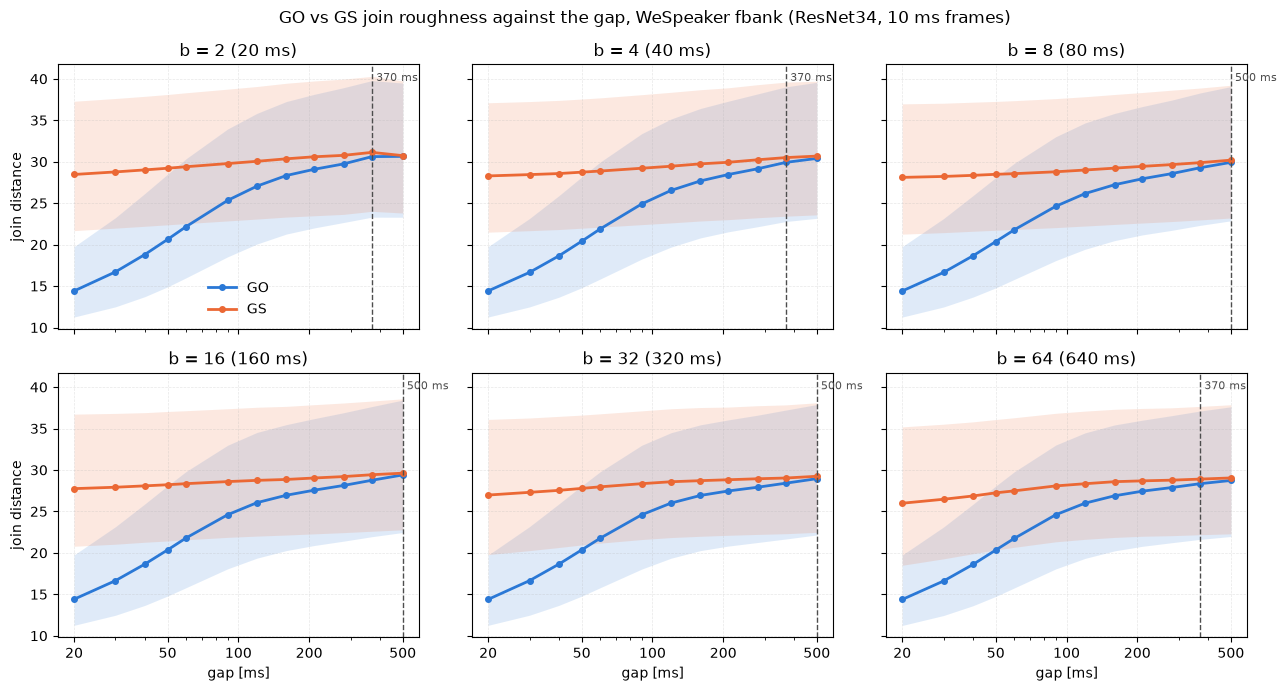

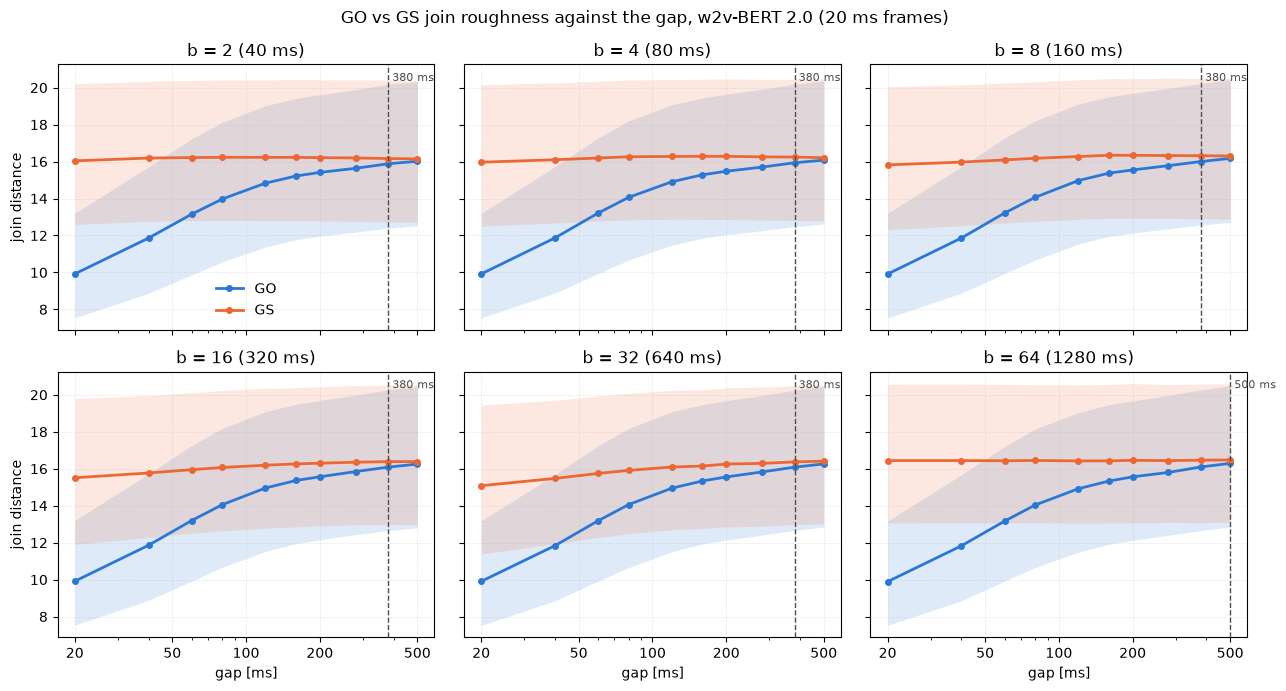

In [6]:
GO_COLOR, GS_COLOR = "#2a78d6", "#eb6834"


def gap_axis(ax):
    # Log-scaled gap axis with plain millisecond ticks.
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([20, 50, 100, 200, 500]))
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())


for front_end, label in FRONT_ENDS.items():
    table, period_ms = tables[front_end], frame_config(front_end).frame_period_s * 1000
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
    for ax, b in zip(axes.flat, BLOCK_SIZES):
        rows = table.loc[b][table.loc[b]["judged"]]
        for name, color in (("GO", GO_COLOR), ("GS", GS_COLOR)):
            ax.fill_between(rows["gap [ms]"], rows[f"{name} q25"], rows[f"{name} q75"], color=color, alpha=0.15, linewidth=0)
            ax.plot(rows["gap [ms]"], rows[f"{name} median"], color=color, linewidth=2, marker="o", markersize=4, label=name)
        gap = minimal_gap(table, b)
        if np.isfinite(gap):
            ax.axvline(gap * period_ms, color="0.3", linestyle="--", linewidth=1)
            ax.annotate(f"{gap * period_ms:.0f} ms", (gap * period_ms, 1), xycoords=("data", "axes fraction"),
                        xytext=(3, -12), textcoords="offset points", fontsize=8, color="0.3")
        ax.set_title(f"b = {b} ({b * period_ms:.0f} ms)")
        gap_axis(ax)
        ax.grid(alpha=0.3, linestyle="--", linewidth=0.5)
    for ax in axes[-1]:
        ax.set_xlabel("gap [ms]")
    for ax in axes[:, 0]:
        ax.set_ylabel("join distance")
    axes[0, 0].legend(frameon=False)
    fig.suptitle(f"GO vs GS join roughness against the gap, {label}")
    fig.tight_layout()
    plt.show()

## Effect sizes against the gap

Left: GS's median join distance relative to GO's; the grey band is the tolerance. Right: the share of utterances whose GS joins are rougher than their GO joins; 0.5 means equally rough. One line per block size.

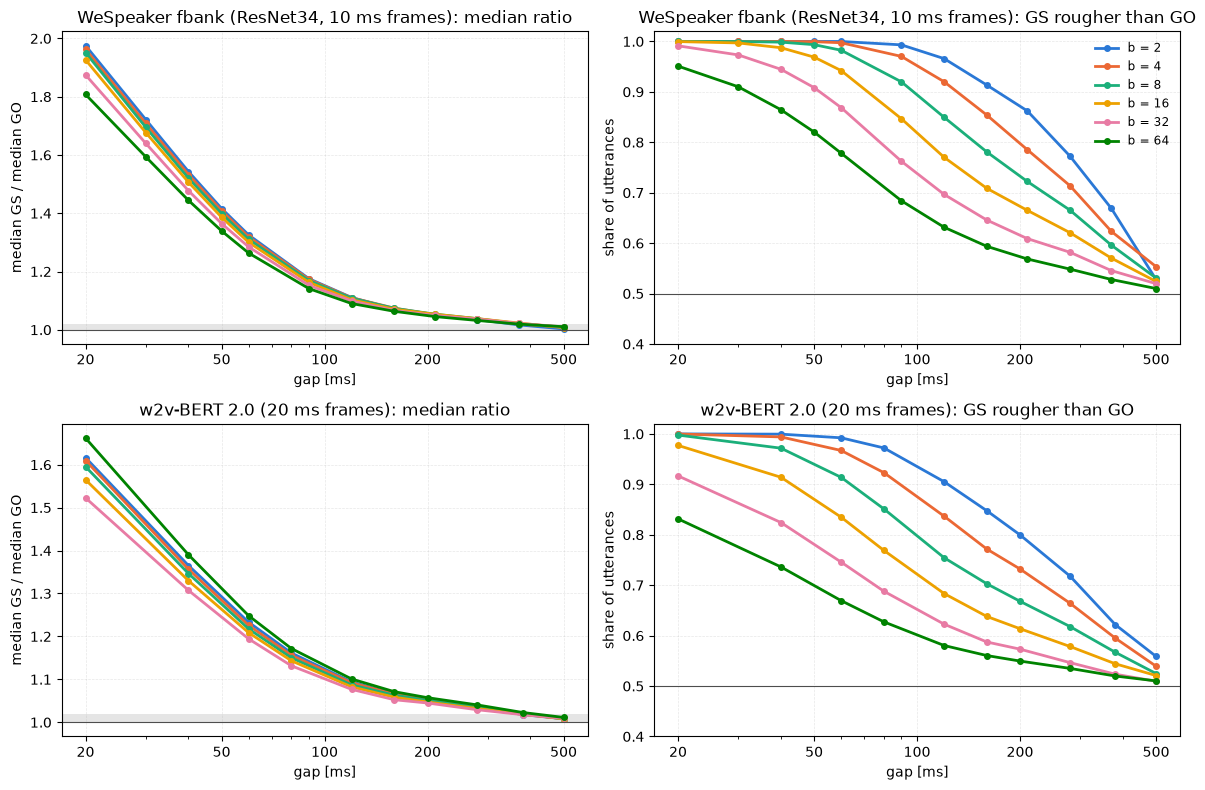

In [7]:
B_COLORS = dict(zip(BLOCK_SIZES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
fig, axes = plt.subplots(len(FRONT_ENDS), 2, figsize=(12, 4 * len(FRONT_ENDS)), squeeze=False)
for row, (front_end, label) in zip(axes, FRONT_ENDS.items()):
    table, period_ms = tables[front_end], frame_config(front_end).frame_period_s * 1000
    for b in BLOCK_SIZES:
        rows = table.loc[b][table.loc[b]["judged"]]
        for ax, column in zip(row, ("GS/GO median", "share GS > GO")):
            ax.plot(rows["gap [ms]"], rows[column], color=B_COLORS[b], linewidth=2, marker="o", markersize=4, label=f"b = {b}")
    row[0].axhspan(1, 1 + TOLERANCE, color="0.5", alpha=0.2, linewidth=0)
    row[0].axhline(1, color="0.3", linewidth=0.8)
    row[1].axhline(0.5, color="0.3", linewidth=0.8)
    row[0].set(ylabel="median GS / median GO", title=f"{label}: median ratio")
    row[1].set(ylabel="share of utterances", title=f"{label}: GS rougher than GO", ylim=(0.4, 1.02))
    for ax in row:
        gap_axis(ax)
        ax.set_xlabel("gap [ms]")
        ax.grid(alpha=0.3, linestyle="--", linewidth=0.5)
axes[0, 1].legend(frameon=False, fontsize="small")
fig.tight_layout()
plt.show()

## Distributions

The densities of all GO and GS join distances at every swept gap, for one block size (`DISTRIBUTION_B`), one row per front-end. GS's distribution barely moves with the gap; GO's moves right until it lies on top of GS's.

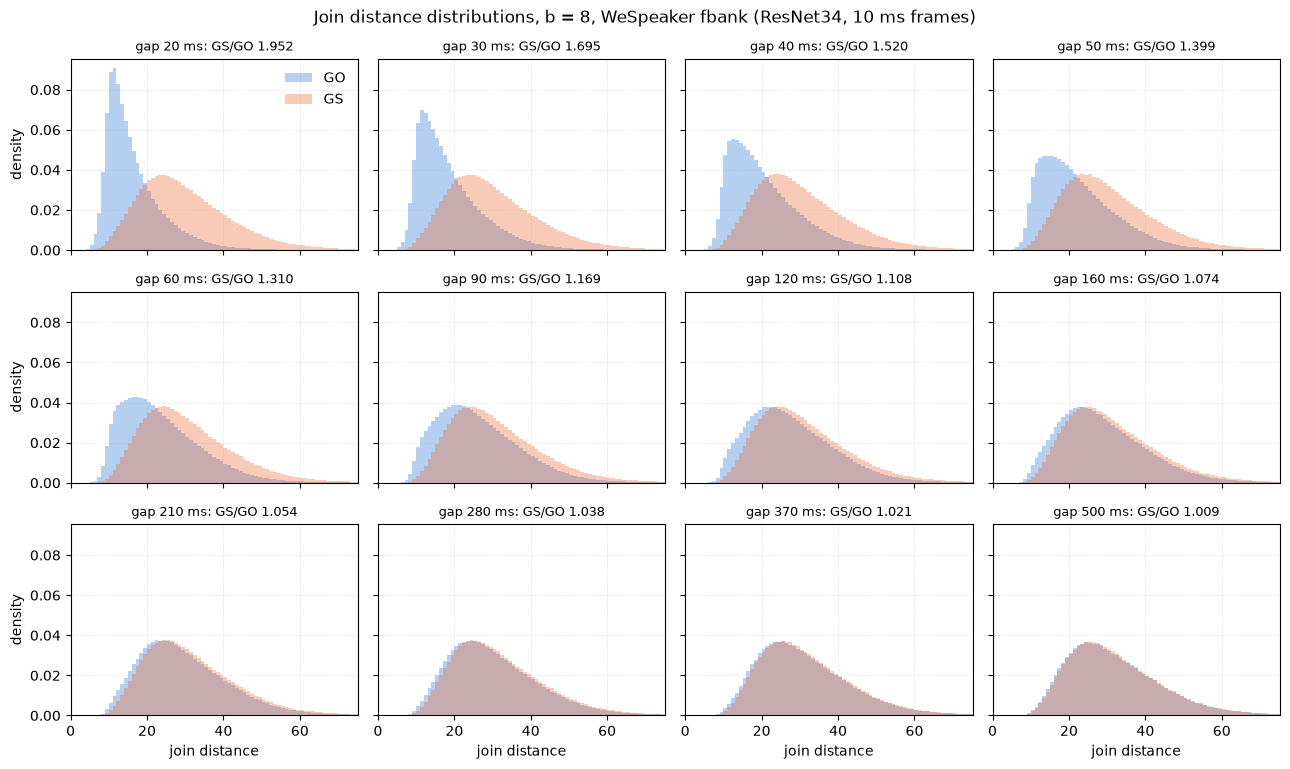

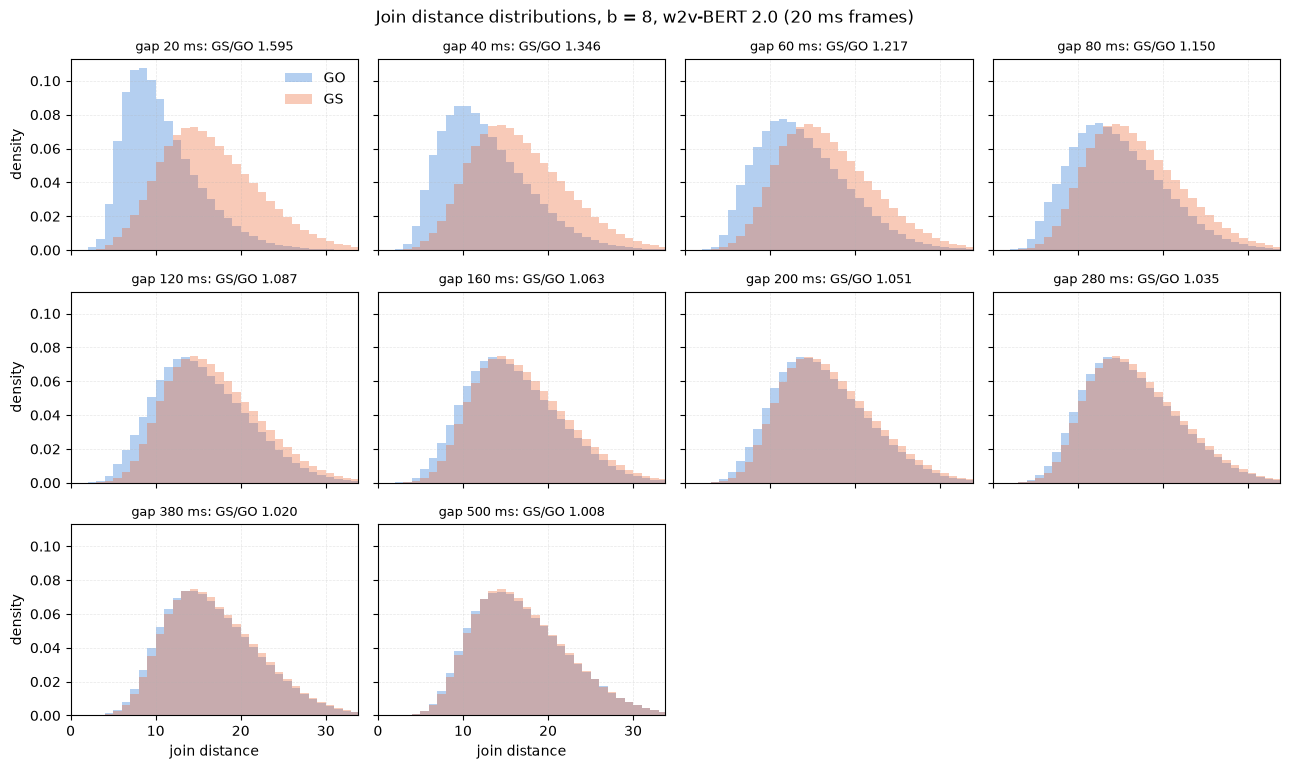

In [8]:
DISTRIBUTION_B = 8
centers = (np.arange(NUM_BINS) + 0.5) * BIN_WIDTH
REBIN = 20  # bins merged for plotting: 1-unit wide bars of distance
for front_end, label in FRONT_ENDS.items():
    r, table, period_ms = results[front_end], tables[front_end], frame_config(front_end).frame_period_s * 1000
    gaps = [g for g in r["gaps"] if table.loc[(DISTRIBUTION_B, g), "judged"]]
    columns = 4
    fig, axes = plt.subplots(-(-len(gaps) // columns), columns, figsize=(13, 2.6 * -(-len(gaps) // columns)),
                             sharex=True, sharey=True, squeeze=False)
    upper = max(quantile(r["counts"][r["keys"].index((DISTRIBUTION_B, g)), 1], 0.995) for g in gaps)
    for ax, g in zip(axes.flat, gaps):
        k = r["keys"].index((DISTRIBUTION_B, g))
        for strategy, (name, color) in enumerate((("GO", GO_COLOR), ("GS", GS_COLOR))):
            counts = r["counts"][k, strategy].reshape(-1, REBIN).sum(axis=1)
            ax.stairs(counts / counts.sum() / (BIN_WIDTH * REBIN), np.arange(len(counts) + 1) * BIN_WIDTH * REBIN,
                      color=color, fill=True, alpha=0.35, label=name)
        stats = table.loc[(DISTRIBUTION_B, g)]
        ax.set_title(f"gap {g * period_ms:.0f} ms: GS/GO {stats['GS/GO median']:.3f}", fontsize=9)
        ax.set_xlim(0, upper)
        ax.grid(alpha=0.3, linestyle="--", linewidth=0.5)
    for ax in axes.flat[len(gaps):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("join distance")
    for ax in axes[:, 0]:
        ax.set_ylabel("density")
    axes[0, 0].legend(frameon=False)
    fig.suptitle(f"Join distance distributions, b = {DISTRIBUTION_B}, {label}")
    fig.tight_layout()
    plt.show()

# Extended utterances

Most VoxCeleb1-H utterances are too short for the gapped spans a gap of several hundred ms needs. Every utterance of a VoxCeleb1 video folder is of the same speaker, so each trial utterance is extended by the other utterances (*parts*) of its video: its own features followed by the others', in file order. Every part is featurized on its own, so it gets its own utterance normalization (WeSpeaker's mean subtraction, w2v-BERT's z-score), which removes level and channel offsets between the parts.

The inputs are then cut from the extended utterance exactly as above. A *join* is now every two consecutive input positions whose frames weren't consecutive in the audio: a gap or a reordering, as above, or a part boundary, also one inside a block (which GO and GS share). A join is *cross-part* if its two frames come from different parts. GS's random block order joins different parts far more often than GO's gaps, so its joins may stay rougher at any gap; the within-part and cross-part medians show whether they do.

**Criteria.** *Equal medians*: GS's median join distance within `TOLERANCE` of GO's, as above but two-sided. *Equal distributions*: additionally the quartiles within `TOLERANCE`, and the share of utterances with rougher GS joins within 0.5 ± `SHARE_TOLERANCE`, as cross-part joins may form a tail that the median doesn't show. The sweep goes up to `EXTENDED_MAX_GAP_MS` (2 s), as GS's cross-part joins may need longer gaps than 500 ms.

**Choosing the gap.** One gap for every b: the largest of the minimal gaps (equal distributions) of the block sizes that reach one. The coverage table gives, at that gap, the utterances long enough per b and the usable trials: both utterances long enough and from different videos (two utterances of one video would share their audio once extended).

In [ ]:
EXTENDED_MAX_GAP_MS = 2000  # GS's cross-part joins may need longer gaps than 2 * SUPRASEGMENTAL_MS
EXTENDED_NUM_GAPS = 16
SHARE_TOLERANCE = 0.05      # share of utterances with rougher GS joins within 0.5 ± this
WITHIN_GO, CROSS_GO, WITHIN_GS, CROSS_GS = range(4)  # histogram rows per (b, g)

with open(vox1_root / "list_test_hard2.txt") as f:
    trials = [line.split() for line in f]
video_of = lambda path: path.rsplit("/", 1)[0]
videos = {}
for index, path in enumerate(paths):
    videos.setdefault(video_of(path), []).append((index, path))


def extended_gaps(front_end):
    period_ms = frame_config(front_end).frame_period_s * 1000
    gaps_ms = np.geomspace(PHONE_MS / 4, EXTENDED_MAX_GAP_MS, EXTENDED_NUM_GAPS)
    return sorted({max(1, round(ms / period_ms)) for ms in gaps_ms})


def video_join_distances(video, trial_utterances, front_end, segment_length, gaps):
    # Per trial utterance of one video: its extended utterance's length in frames, and per (b, g) whose span fits,
    # GO's and GS's join distances with a flag per join whether it is cross-part. Runs in a worker; featurizes every
    # part of the video once, on its own.
    directory = vox1_root / "wav" / video
    parts = sorted(part.name for part in directory.glob("*.wav"))
    features = {part: featurize_waveform(sf.read(str(directory / part), dtype="float32")[0], frame_config(front_end))
                for part in parts}
    result = {}
    for index, path in trial_utterances:
        own = path.rsplit("/", 1)[1]
        order = [own, *(part for part in parts if part != own)]
        extended = np.concatenate([features[part] for part in order])
        part_of = np.repeat(np.arange(len(order)), [len(features[part]) for part in order])
        frames = np.arange(len(extended))[:, None]
        rng = np.random.default_rng(index)  # GS's block order, one Generator per trial utterance
        joins = {}
        for b in BLOCK_SIZES:
            for g in gaps:
                if len(extended) < gapped_span(segment_length, b, g):
                    continue
                cut = []
                for source in input_sources(frames, segment_length, b, g, rng):
                    cross = part_of[source[1:]] != part_of[source[:-1]]
                    at = np.flatnonzero((np.diff(source) != 1) | cross) + 1
                    distances = np.linalg.norm(extended[source[at]] - extended[source[at - 1]], axis=1)
                    cut += [distances.astype(np.float32), cross[at - 1]]
                joins[b, g] = cut
        result[path] = (len(extended), joins)
    return result


def extended_sweep(front_end):
    # As sweep, over the extended utterances: per (b, g), histograms of the join distances split into GO/GS and
    # within-/cross-part, and per trial utterance the mean GO and GS join distance (paired).
    segment_length = DataConfig(segment_duration=SEGMENT_DURATION).segment_length(frame_config(front_end))
    gaps = extended_gaps(front_end)
    keys = [(b, g) for b in BLOCK_SIZES for g in gaps]
    slot = {key: i for i, key in enumerate(keys)}
    counts = np.zeros((len(keys), 4, NUM_BINS), dtype=np.int64)
    means = {key: [] for key in keys}
    lengths = {}
    entries = [(partial(video_join_distances, video, members, front_end, segment_length, gaps), video)
               for video, members in videos.items()]
    began, done = time.monotonic(), 0
    for result, _ in resolved_utterances(entries, num_workers=os.cpu_count()):
        indices = []
        for path, (length, joins) in result.items():
            lengths[path] = length
            for key, (go_d, go_cross, gs_d, gs_cross) in joins.items():
                for row, d, cross in ((WITHIN_GO, go_d, go_cross), (WITHIN_GS, gs_d, gs_cross)):
                    rows = (slot[key] * 4 + row + cross) * NUM_BINS  # row + 1 is the cross-part row
                    indices.append(rows + np.minimum((d / BIN_WIDTH).astype(np.int64), NUM_BINS - 1))
                means[key].append((go_d.mean(), gs_d.mean()))
        if indices:
            counts += np.bincount(np.concatenate(indices), minlength=counts.size).reshape(counts.shape)
        done += len(result)
        if done // 20000 > (done - len(result)) // 20000:
            print(f"  {front_end}: {done}/{len(paths)} utterances, {time.monotonic() - began:.0f} s")
    return dict(segment_length=segment_length, gaps=gaps, keys=keys, counts=counts, lengths=lengths,
                means={key: np.array(values).reshape(-1, 2) for key, values in means.items()})


extended = {front_end: extended_sweep(front_end) for front_end in FRONT_ENDS}

In [ ]:
def extended_statistics(front_end):
    r = extended[front_end]
    period_ms = frame_config(front_end).frame_period_s * 1000
    rows = []
    for k, (b, g) in enumerate(r["keys"]):
        paired, counts = r["means"][b, g], r["counts"][k]
        row = {"b": b, "gap [frames]": g, "gap [ms]": g * period_ms, "utterances": len(paired)}
        if len(paired):
            pooled = {"GO": counts[WITHIN_GO] + counts[CROSS_GO], "GS": counts[WITHIN_GS] + counts[CROSS_GS]}
            for name, c in pooled.items():
                for q, label in ((0.25, "q25"), (0.5, "median"), (0.75, "q75")):
                    row[f"{name} {label}"] = quantile(c, q)
            for label in ("q25", "median", "q75"):
                row[f"GS/GO {label}"] = row[f"GS {label}"] / row[f"GO {label}"]
            row["share GS > GO"] = np.mean(paired[:, 1] > paired[:, 0])
            for name, within, cross in (("GO", WITHIN_GO, CROSS_GO), ("GS", WITHIN_GS, CROSS_GS)):
                row[f"{name} cross-part share"] = counts[cross].sum() / pooled[name].sum()
                for part, c in (("within", counts[within]), ("cross", counts[cross])):
                    row[f"{name} {part} median"] = quantile(c, 0.5) if c.sum() else np.nan
            row["overflow"] = counts[:, -1].sum()
        rows.append(row)
    table = pd.DataFrame(rows).set_index(["b", "gap [frames]"])
    table["judged"] = table["utterances"] >= MIN_UTTERANCES
    table["equal medians"] = table["judged"] & ((table["GS/GO median"] - 1).abs() <= TOLERANCE)
    table["equal distributions"] = (
        table["equal medians"]
        & ((table["GS/GO q25"] - 1).abs() <= TOLERANCE) & ((table["GS/GO q75"] - 1).abs() <= TOLERANCE)
        & ((table["share GS > GO"] - 0.5).abs() <= SHARE_TOLERANCE))
    return table


extended_tables = {front_end: extended_statistics(front_end) for front_end in FRONT_ENDS}
for front_end, table in extended_tables.items():
    print(f"{front_end}: {table['overflow'].sum():.0f} join distances above {MAX_DISTANCE} put into the last bin")

rows, chosen = [], {}
for front_end in FRONT_ENDS:
    period_ms = frame_config(front_end).frame_period_s * 1000
    for b in BLOCK_SIZES:
        rows.append({"front-end": front_end, "b": b, "block [ms]": b * period_ms,
                     **{f"minimal gap [ms], {criterion}": minimal_gap(extended_tables[front_end], b, criterion) * period_ms
                        for criterion in ("equal medians", "equal distributions")}})
    gaps = [minimal_gap(extended_tables[front_end], b, "equal distributions") for b in BLOCK_SIZES]
    chosen[front_end] = max((g for g in gaps if np.isfinite(g)), default=np.nan)
print("Minimal gap per criterion (NaN: not reached within the sweep, or too few utterances long enough):")
display(pd.DataFrame(rows).style.format(precision=0, na_rep="–").hide(axis="index"))


def coverage(front_end, g):
    # At gap g, per b: the trial utterances whose extended utterance is long enough, and the usable trials (both
    # utterances long enough, from different videos).
    r = extended[front_end]
    rows = []
    for b in BLOCK_SIZES:
        span = gapped_span(r["segment_length"], b, g)
        long_enough = {path for path, length in r["lengths"].items() if length >= span}
        usable = [t for t in trials if video_of(t[1]) != video_of(t[2]) and t[1] in long_enough and t[2] in long_enough]
        rows.append({"b": b, "span [s]": span * frame_config(front_end).frame_period_s,
                     "utterances": len(long_enough), "share of utterances": len(long_enough) / len(paths),
                     "usable trials": len(usable), "target trials": sum(t[0] == "1" for t in usable)})
    return pd.DataFrame(rows).set_index("b")


for front_end, label in FRONT_ENDS.items():
    g = chosen[front_end]
    if not np.isfinite(g):
        print(f"{label}: no block size reaches equal distributions within the sweep")
        continue
    period_ms = frame_config(front_end).frame_period_s * 1000
    print(f"{label}: chosen gap {g} frames = {g * period_ms:.0f} ms (of {len(trials)} trials)")
    display(coverage(front_end, g).style.format({"span [s]": "{:.1f}", "share of utterances": "{:.1%}"}))

## Statistics per block size and gap (extended utterances)

In [ ]:
for front_end, label in FRONT_ENDS.items():
    print(label)
    display(extended_tables[front_end].drop(columns=["overflow"]).style.format(precision=3))

## Medians against the gap (extended utterances)

As above, plus GS's within-part (dotted) and cross-part (dashed) medians. If GS's cross-part joins stay above GO's at large gaps, the part boundaries, not the gap, keep the joins unequal. The dashed vertical line marks the minimal gap (equal distributions).

In [ ]:
for front_end, label in FRONT_ENDS.items():
    table, period_ms = extended_tables[front_end], frame_config(front_end).frame_period_s * 1000
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
    for ax, b in zip(axes.flat, BLOCK_SIZES):
        rows = table.loc[b][table.loc[b]["judged"]]
        for name, color in (("GO", GO_COLOR), ("GS", GS_COLOR)):
            ax.fill_between(rows["gap [ms]"], rows[f"{name} q25"], rows[f"{name} q75"], color=color, alpha=0.15, linewidth=0)
            ax.plot(rows["gap [ms]"], rows[f"{name} median"], color=color, linewidth=2, marker="o", markersize=4, label=name)
        ax.plot(rows["gap [ms]"], rows["GS within median"], color=GS_COLOR, linewidth=1.5, linestyle=":", label="GS within-part")
        ax.plot(rows["gap [ms]"], rows["GS cross median"], color=GS_COLOR, linewidth=1.5, linestyle="--", label="GS cross-part")
        gap = minimal_gap(table, b, "equal distributions")
        if np.isfinite(gap):
            ax.axvline(gap * period_ms, color="0.3", linestyle="--", linewidth=1)
            ax.annotate(f"{gap * period_ms:.0f} ms", (gap * period_ms, 1), xycoords=("data", "axes fraction"),
                        xytext=(3, -12), textcoords="offset points", fontsize=8, color="0.3")
        ax.set_title(f"b = {b} ({b * period_ms:.0f} ms)")
        gap_axis(ax)
        ax.xaxis.set_major_locator(FixedLocator([20, 50, 100, 200, 500, 1000, 2000]))
        ax.grid(alpha=0.3, linestyle="--", linewidth=0.5)
    for ax in axes[-1]:
        ax.set_xlabel("gap [ms]")
    for ax in axes[:, 0]:
        ax.set_ylabel("join distance")
    axes[0, 0].legend(frameon=False, fontsize="small")
    fig.suptitle(f"GO vs GS join roughness against the gap, extended utterances, {label}")
    fig.tight_layout()
    plt.show()

## Effect sizes against the gap (extended utterances)

Left: GS's median join distance relative to GO's, with the tolerance band. Middle: the share of utterances whose GS joins are rougher, with 0.5 ± `SHARE_TOLERANCE`. Right: the share of GO's and GS's joins that are cross-part. One line per block size.

In [ ]:
fig, axes = plt.subplots(len(FRONT_ENDS), 3, figsize=(15, 4 * len(FRONT_ENDS)), squeeze=False)
for row, (front_end, label) in zip(axes, FRONT_ENDS.items()):
    table = extended_tables[front_end]
    for b in BLOCK_SIZES:
        rows = table.loc[b][table.loc[b]["judged"]]
        row[0].plot(rows["gap [ms]"], rows["GS/GO median"], color=B_COLORS[b], linewidth=2, marker="o", markersize=4, label=f"b = {b}")
        row[1].plot(rows["gap [ms]"], rows["share GS > GO"], color=B_COLORS[b], linewidth=2, marker="o", markersize=4)
        row[2].plot(rows["gap [ms]"], rows["GS cross-part share"], color=B_COLORS[b], linewidth=2, marker="o", markersize=4)
        row[2].plot(rows["gap [ms]"], rows["GO cross-part share"], color=B_COLORS[b], linewidth=1.5, linestyle=":")
    row[0].axhspan(1 - TOLERANCE, 1 + TOLERANCE, color="0.5", alpha=0.2, linewidth=0)
    row[1].axhspan(0.5 - SHARE_TOLERANCE, 0.5 + SHARE_TOLERANCE, color="0.5", alpha=0.2, linewidth=0)
    row[0].set(ylabel="median GS / median GO", title=f"{label}: median ratio")
    row[1].set(ylabel="share of utterances", title=f"{label}: GS rougher than GO", ylim=(0.4, 1.02))
    row[2].set(ylabel="share of joins", title=f"{label}: cross-part joins (GS solid, GO dotted)", ylim=(0, 1))
    for ax in row:
        gap_axis(ax)
        ax.xaxis.set_major_locator(FixedLocator([20, 50, 100, 200, 500, 1000, 2000]))
        ax.set_xlabel("gap [ms]")
        ax.grid(alpha=0.3, linestyle="--", linewidth=0.5)
axes[0, 0].legend(frameon=False, fontsize="small")
fig.tight_layout()
plt.show()

## Distributions (extended utterances)

GO's and GS's join distance densities at every swept gap with enough utterances, for `DISTRIBUTION_B`.

In [ ]:
for front_end, label in FRONT_ENDS.items():
    r, table, period_ms = extended[front_end], extended_tables[front_end], frame_config(front_end).frame_period_s * 1000
    gaps = [g for g in r["gaps"] if table.loc[(DISTRIBUTION_B, g), "judged"]]
    columns = 4
    fig, axes = plt.subplots(-(-len(gaps) // columns), columns, figsize=(13, 2.6 * -(-len(gaps) // columns)),
                             sharex=True, sharey=True, squeeze=False)
    pooled = {g: (r["counts"][r["keys"].index((DISTRIBUTION_B, g))][[WITHIN_GO, CROSS_GO]].sum(axis=0),
                  r["counts"][r["keys"].index((DISTRIBUTION_B, g))][[WITHIN_GS, CROSS_GS]].sum(axis=0)) for g in gaps}
    upper = max(quantile(pooled[g][1], 0.995) for g in gaps)
    for ax, g in zip(axes.flat, gaps):
        for counts, (name, color) in zip(pooled[g], (("GO", GO_COLOR), ("GS", GS_COLOR))):
            counts = counts.reshape(-1, REBIN).sum(axis=1)
            ax.stairs(counts / counts.sum() / (BIN_WIDTH * REBIN), np.arange(len(counts) + 1) * BIN_WIDTH * REBIN,
                      color=color, fill=True, alpha=0.35, label=name)
        ax.set_title(f"gap {g * period_ms:.0f} ms: GS/GO {table.loc[(DISTRIBUTION_B, g), 'GS/GO median']:.3f}", fontsize=9)
        ax.set_xlim(0, upper)
        ax.grid(alpha=0.3, linestyle="--", linewidth=0.5)
    for ax in axes.flat[len(gaps):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("join distance")
    for ax in axes[:, 0]:
        ax.set_ylabel("density")
    axes[0, 0].legend(frameon=False)
    fig.suptitle(f"Join distance distributions, extended utterances, b = {DISTRIBUTION_B}, {label}")
    fig.tight_layout()
    plt.show()